# Домашнее задание №2. Аудит A/B-эксперимента

Сосновский Егор, М26-515

## Описание задания

Команда провела эксперимент, но есть подозрение, что аналитик нарушил протокол. Нужно проверить данные, найти нарушения и решить, стоит ли внедрять фичу. Выводы должны опираться на числа из полученной выборки.

Исходный файл `exp_data_seed_195600.csv` содержит:

- `user_id` - идентификатор пользователя.
- `variant` - группа control или test.
- `converted` - целевое действие, 0 или 1.
- `error_flag` - ошибка загрузки страницы, 0 или 1.
- `weekend` - признак выходного дня, 0 или 1.
- `platform` - платформа 0, 1 или 2.
- `entry_time` - время входа, заданное долей дня от 0 до 1.

Ноутбук читает отдельный CSV. Для повторного запуска в Colab этот файл нужно загрузить в рабочую среду ноутбука. Результаты расчётов и графики уже сохранены.

## 1. Загрузка данных и проверки до анализа

### Условие

Сгенерируйте файл `exp_data_seed_{MY_SEED}.csv` по коду задания. Данные должны быть уникальными. Загрузите файл, выполните проверки до анализа и выведите размеры групп, среднюю конверсию и частоту ошибок.

### Решение

seed `195600` выбран один раз командой из задания. CSV содержит 6585 пользователей. генератор выполнен без изменения параметров и порядка случайных вызовов. данные не подбирались повторной генерацией. при запуске этого ноутбука файл только читается.

проверяются столбцы, пропуски, повторные пользователи, названия групп, значения бинарных признаков, платформы и диапазон времени. строка соответствует одному пользователю. ошибки загрузки остаются в выборке, иначе защитная метрика была бы занижена.

`pd.to_timedelta(..., unit='D')` переводит долю дня в продолжительность. умножение `entry_time` на 24 даёт часы. календарной даты в данных нет, поэтому по этому времени нельзя восстановить день недели. `weekend` читается как отдельный признак.

`groupby('variant')` собирает показатели по группам. у столбца из нулей и единиц `sum` считает события, а `mean` даёт их частоту. порог значимости 0,05 используется во всех проверках. для трёх платформ далее применяется отдельная поправка Бонферрони.

### Код

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare, ttest_ind, mannwhitneyu, norm, binomtest
from IPython.display import display

ALPHA = 0.05
Z_CRIT = norm.ppf(1 - ALPHA / 2)
GROUPS = ['control', 'test']
COLORS = ['#245B8A', '#C05B22']
DATA_FILE = 'exp_data_seed_195600.csv'

# итоговая таблица должна показывать причины решения полностью
pd.set_option('display.max_colwidth', None)

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 120,
})

# все показатели должны считаться на отдельном исходном CSV
try:
    df = pd.read_csv(DATA_FILE)
except FileNotFoundError:
    raise FileNotFoundError(
        f'Загрузите {DATA_FILE} в рабочую папку ноутбука и запустите ячейки заново.'
    ) from None

required_columns = {
    'user_id', 'variant', 'converted', 'error_flag',
    'weekend', 'platform', 'entry_time',
}
if set(df.columns) != required_columns:
    raise ValueError('Названия столбцов не соответствуют исходному CSV.')
if df.empty:
    raise ValueError('В CSV нет пользователей.')

# недопустимые значения останавливают анализ, строки молча не удаляются
problems = []
if df.isna().any().any():
    problems.append('Есть пропуски.')
if df.user_id.duplicated().any():
    problems.append('Есть повторные user_id.')
if set(df.variant.unique()) != set(GROUPS):
    problems.append('Должны присутствовать обе группы: control и test.')
for column in ['converted', 'error_flag', 'weekend']:
    if not df[column].isin([0, 1]).all():
        problems.append(f'{column} должен содержать только 0 и 1.')
if not df.platform.isin([0, 1, 2]).all():
    problems.append('Допустимы только платформы 0, 1 и 2.')
if not np.isfinite(df.entry_time).all() or not df.entry_time.between(0, 1, inclusive='left').all():
    problems.append('Время входа должно быть конечным и находиться от 0 до 1, не включая 1.')
if not pd.api.types.is_numeric_dtype(df.user_id):
    problems.append('user_id должен быть числом.')
elif not np.isfinite(df.user_id).all() or (df.user_id < 0).any() or (df.user_id % 1 != 0).any():
    problems.append('user_id должен быть целым неотрицательным числом.')
if problems:
    raise ValueError(' '.join(problems))

# длительность и часы добавляются только в память, исходный CSV не меняется
df['time_delta'] = pd.to_timedelta(df.entry_time, unit='D')
df['entry_hours'] = 24 * df.entry_time

summary = df.groupby('variant').agg(
    users=('user_id', 'size'),
    conversions=('converted', 'sum'),
    conversion_rate=('converted', 'mean'),
    errors=('error_flag', 'sum'),
    error_rate=('error_flag', 'mean'),
    weekend_share=('weekend', 'mean'),
).reindex(GROUPS)
summary['errors'] = summary.errors.astype(int)
control = df.loc[df.variant == 'control']
test = df.loc[df.variant == 'test']

### Проверка

In [2]:
# проверяем, что прочитана полная выборка, предоставленная с этой работой
assert len(df) == 6585
assert df.user_id.is_unique
print(f'Файл: {DATA_FILE}')
print(f'Пользователей: {len(df)}')
print(f'Пропуски: {int(df.isna().sum().sum())}')
print(f'Повторные user_id: {int(df.user_id.duplicated().sum())}')
display(df.head())

view = summary.rename(columns={
    'users': 'Пользователи', 'conversions': 'Конверсии',
    'conversion_rate': 'Конверсия', 'errors': 'Ошибки',
    'error_rate': 'Частота ошибок', 'weekend_share': 'Доля выходных',
}).copy()
for column in ['Конверсия', 'Частота ошибок', 'Доля выходных']:
    view[column] = view[column].map('{:.2%}'.format)
display(view)

Файл: exp_data_seed_195600.csv
Пользователей: 6585
Пропуски: 0
Повторные user_id: 0


,user_id,variant,converted,error_flag,weekend,platform,entry_time,time_delta,entry_hours
0,0,test,0,0.0,0,0,0.060824,0 days 01:27:35.151097628,1.459764
1,1,test,0,0.0,0,0,0.432982,0 days 10:23:29.613109577,10.391559
2,2,control,0,0.0,0,0,0.913837,0 days 21:55:55.550690382,21.932097
3,3,control,0,0.0,0,1,0.262452,0 days 06:17:55.882587946,6.298856
4,4,control,1,0.0,0,1,0.134084,0 days 03:13:04.828730174,3.218008


,Пользователи,Конверсии,Конверсия,Ошибки,Частота ошибок,Доля выходных
variant,,,,,,
control,4017,420,10.46%,78,1.94%,13.12%
test,2568,325,12.66%,142,5.53%,57.13%


пропусков и повторных пользователей нет. в control 4017 пользователей, в test 2568. конверсии составляют 10,46% и 12,66%, ошибки 1,94% и 5,53%. эти показатели пока только описывают выборку. корректность назначения групп проверяется дальше.

## 2. Проверка соотношения групп, SRM

### Условие

Проверьте SRM с помощью хи-квадрат теста. Ожидаемое соотношение 50/50. Выведите p-value и вердикт «SRM обнаружен» или «SRM нет».

### Решение

при распределении 50/50 ожидается по `6585 / 2 = 3292,5` пользователя. ожидаемые количества могут быть дробными. реальные количества равны 4017 и 2568.

`chisquare()` проверяет расхождение реальных и ожидаемых количеств. нулевая гипотеза: каждый вариант назначается с вероятностью 0,5. проверка касается именно плана 50/50. если бы заранее был задан другой план, ожидаемые количества пришлось бы изменить.

### Код

In [3]:
# порядок групп в обоих массивах одинаковый: control, затем test
observed = summary.users.to_numpy()
expected = np.array([len(df) / 2, len(df) / 2])
srm_result = chisquare(f_obs=observed, f_exp=expected)
p_srm = float(srm_result.pvalue)
srm_warning = p_srm < ALPHA

### Проверка

In [4]:
print(f'Фактически: control = {observed[0]}, test = {observed[1]}')
print(f'Ожидалось в каждой группе: {expected[0]:.1f}')
print(f'Доля test: {len(test) / len(df):.2%}')
print(f'Хи-квадрат: {srm_result.statistic:.3f}')
print(f'p-value: {p_srm:.3g}')
print('SRM обнаружен' if srm_warning else 'SRM нет')

Фактически: control = 4017, test = 2568
Ожидалось в каждой группе: 3292.5
Доля test: 39.00%
Хи-квадрат: 318.846
p-value: 2.58e-71
SRM обнаружен


в test попало 39,00% пользователей. p-value примерно 2,58 · 10⁻⁷¹, план 50/50 нарушен. итоговые группы зависят от нескольких переопределений `variant`, поэтому комментарий генератора о 55/45 не описывает фактическое распределение.

## 3. Баланс ковариаты weekend

### Условие

Проверьте баланс хотя бы одной ковариаты, `weekend` или `entry_time`, с помощью t-test или U-теста. Есть ли значимые различия? Объясните, может ли признак быть смешивающим фактором.

### Решение

для `weekend` среднее равно доле пользователей с признаком 1. сравниваются эти доли через t-тест Уэлча с `equal_var=False`. он не требует равенства дисперсий. нормальность отдельных значений 0/1 не предполагается, приближение для средних опирается на большие размеры групп.

значимый дисбаланс сам по себе не доказывает смешение. в генераторе есть дополнительная информация: `weekend` участвует и в назначении варианта, и в формуле конверсии `0.1 + 0.05 * weekend`. поэтому простое сравнение конверсий смешивает влияние состава групп и варианта.

на первом графике показаны размеры групп, на втором доля пользователей с `weekend = 1`.

### Код

In [5]:
weekend_result = ttest_ind(
    test.weekend, control.weekend,
    equal_var=False, alternative='two-sided',
)
p_weekend = float(weekend_result.pvalue)
weekend_warning = p_weekend < ALPHA
weekend_control = control.weekend.mean()
weekend_test = test.weekend.mean()
weekend_diff = weekend_test - weekend_control

### Проверка

Доля weekend = 1 в control: 13.12%
Доля weekend = 1 в test: 57.13%
Разница test - control: 44.007 п.п.
t-статистика: 39.552
p-value: 5.25e-290
Дисбаланс weekend обнаружен. Возможен смешивающий фактор.


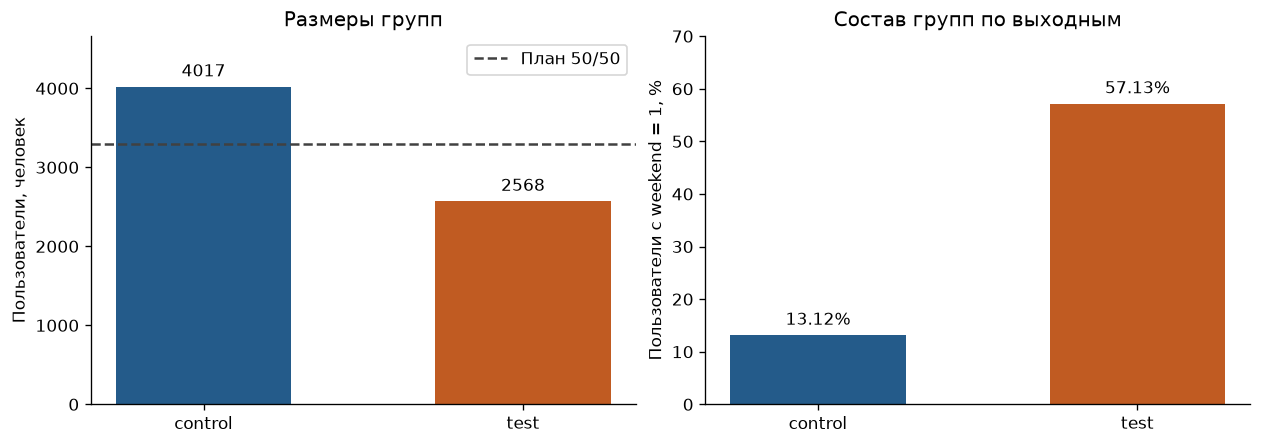

In [6]:
print(f'Доля weekend = 1 в control: {weekend_control:.2%}')
print(f'Доля weekend = 1 в test: {weekend_test:.2%}')
print(f'Разница test - control: {100 * weekend_diff:.3f} п.п.')
print(f't-статистика: {weekend_result.statistic:.3f}')
print(f'p-value: {p_weekend:.3g}')
if weekend_warning:
    print('Дисбаланс weekend обнаружен. Возможен смешивающий фактор.')
else:
    print('Значимого дисбаланса weekend не обнаружено.')

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.6), layout='constrained')
bars = axes[0].bar(GROUPS, observed, color=COLORS, width=0.55)
axes[0].bar_label(bars, padding=4)
axes[0].axhline(expected[0], color='#414141', linestyle='--', label='План 50/50')
axes[0].set_ylim(0, observed.max() * 1.16)
axes[0].set_ylabel('Пользователи, человек')
axes[0].set_title('Размеры групп')
axes[0].legend()

shares = 100 * np.array([weekend_control, weekend_test])
bars = axes[1].bar(GROUPS, shares, color=COLORS, width=0.55)
axes[1].bar_label(bars, labels=[f'{x:.2f}%' for x in shares], padding=4)
axes[1].set_ylim(0, 70)
axes[1].set_ylabel('Пользователи с weekend = 1, %')
axes[1].set_title('Состав групп по выходным')
plt.show()

доля выходных равна 13,12% в control и 57,13% в test. разница составляет 44,01 процентного пункта, p-value примерно 5,25 · 10⁻²⁹⁰. группы сильно различаются по признаку, который влияет на конверсию. для дальнейшего сравнения потребуется коррекция состава.

## 4. Предварительный анализ конверсии

### Условие

Проведите Z-тест для пропорций или t-тест. Рассчитайте lift, 95% доверительный интервал и p-value. Не делайте вывод о значимости до проверки peeking, множественных сравнений и защитной метрики.

### Решение

`compare_proportions()` считает разницу долей `p_test - p_control`. для Z-теста используется общая доля конверсий в двух группах. стандартная ошибка при нулевой гипотезе равна корню из `p_pool * (1 - p_pool) * (1 / n_control + 1 / n_test)`.

Z-статистика равна разнице долей, делённой на эту ошибку. двустороннее p-value вычисляется через оба хвоста стандартного нормального распределения. перед расчётом функция проверяет, что в каждой группе достаточно событий и несобытий.

95% интервал разницы строится с отдельными дисперсиями двух групп: `difference ± 1.96 * se_difference`. это приближённый интервал Уолда для абсолютного изменения. для lift, равного `p_test / p_control - 1`, дополнительно считается приближённый интервал через логарифм отношения долей. процентные пункты и относительные проценты показываются отдельно.

эти расчёты предполагают независимые наблюдения и обычный фиксированный план анализа. уже найденные нарушения назначения делают их описанием связи, а не доказательством причинного эффекта. продуктовый вывод будет после остальных проверок.

### Код

In [7]:
def compare_proportions(data, column):
    # бинарные признаки позволяют получить события через sum, размер через size
    grouped = data.groupby('variant')[column].agg(['sum', 'size']).reindex(GROUPS)
    if grouped.isna().any().any():
        raise ValueError('Для сравнения нужны пользователи обеих групп.')
    n_control = int(grouped.loc['control', 'size'])
    n_test = int(grouped.loc['test', 'size'])
    events_control = int(grouped.loc['control', 'sum'])
    events_test = int(grouped.loc['test', 'sum'])

    # приближение не применяется к редким событиям без проверки частот
    counts = [events_control, n_control - events_control,
              events_test, n_test - events_test]
    if min(counts) < 10:
        raise ValueError('Для этого Z-теста нужно не меньше 10 событий и несобытий в каждой группе.')

    rate_control = events_control / n_control
    rate_test = events_test / n_test
    difference = rate_test - rate_control

    # при нулевой гипотезе обе группы имеют одну вероятность события
    pooled_rate = (events_control + events_test) / (n_control + n_test)
    se_null = np.sqrt(pooled_rate * (1 - pooled_rate) * (1 / n_control + 1 / n_test))
    z_stat = difference / se_null
    p_value = 2 * norm.sf(abs(z_stat))

    # интервал разницы использует отдельную оценку разброса каждой группы
    se_difference = np.sqrt(
        rate_control * (1 - rate_control) / n_control
        + rate_test * (1 - rate_test) / n_test
    )
    ci_low = difference - Z_CRIT * se_difference
    ci_high = difference + Z_CRIT * se_difference

    # lift является относительной разницей, его интервал строится через логарифм отношения
    risk_ratio = rate_test / rate_control
    se_log_ratio = np.sqrt(
        1 / events_test - 1 / n_test + 1 / events_control - 1 / n_control
    )
    lift_low = np.exp(np.log(risk_ratio) - Z_CRIT * se_log_ratio) - 1
    lift_high = np.exp(np.log(risk_ratio) + Z_CRIT * se_log_ratio) - 1

    return {
        'n_control': n_control, 'n_test': n_test,
        'events_control': events_control, 'events_test': events_test,
        'rate_control': rate_control, 'rate_test': rate_test,
        'difference': difference, 'ci_low': ci_low, 'ci_high': ci_high,
        'lift': risk_ratio - 1, 'lift_low': lift_low, 'lift_high': lift_high,
        'z': float(z_stat), 'p_value': float(p_value),
    }

primary = compare_proportions(df, 'converted')

### Проверка

In [8]:
print(f'Конверсия control: {primary["rate_control"]:.2%}')
print(f'Конверсия test: {primary["rate_test"]:.2%}')
print(f'Разница: {100 * primary["difference"]:.3f} п.п.')
print(f'95% ДИ разницы: [{100 * primary["ci_low"]:.3f}, {100 * primary["ci_high"]:.3f}] п.п.')
print(f'Lift: {primary["lift"]:.2%}')
print(f'95% ДИ lift: [{primary["lift_low"]:.2%}, {primary["lift_high"]:.2%}]')
print(f'Z-статистика: {primary["z"]:.3f}')
print(f'p-value без коррекции состава групп: {primary["p_value"]:.6f}')

Конверсия control: 10.46%
Конверсия test: 12.66%
Разница: 2.200 п.п.
95% ДИ разницы: [0.604, 3.797] п.п.
Lift: 21.04%
95% ДИ lift: [5.64%, 38.69%]
Z-статистика: 2.749
p-value без коррекции состава групп: 0.005974


наблюдаемая разница равна +2,200 п.п., 95% интервал от +0,604 до +3,797 п.п. lift равен +21,04%, его интервал от +5,64% до +38,69%. p-value равно 0,005974. решение о запуске по этим числам ещё не принимается.

## 5. Защитная метрика error_flag

### Условие

Проверьте частоту ошибок. Значимо ли она выше в test? Если да, тест должен быть остановлен, даже если первичная метрика выросла.

### Решение

для частоты ошибок используется тот же двусторонний Z-тест. ошибок достаточно для нормального приближения: 78 в control и 142 в test. ухудшение фиксируется, если частота test выше и p-value меньше 0,05.

порог допустимого ухудшения в условии не задан, поэтому используется правило о статистически значимом росте. на графике показаны 95% интервалы Уилсона для отдельных частот. сравнение групп выполняется тестом, а не по пересечению этих интервалов.

### Код

In [9]:
guardrail = compare_proportions(df, 'error_flag')
guardrail_warning = guardrail['difference'] > 0 and guardrail['p_value'] < ALPHA

# интервалы Уилсона ограничены допустимыми значениями долей от 0 до 1
error_intervals = []
for group in GROUPS:
    events = int(summary.loc[group, 'errors'])
    total = int(summary.loc[group, 'users'])
    interval = binomtest(events, total).proportion_ci(confidence_level=0.95, method='wilson')
    error_intervals.append(interval)

### Проверка

Ошибки control: 78 / 4017 = 1.94%
Ошибки test: 142 / 2568 = 5.53%
Разница: 3.588 п.п.
95% ДИ разницы: [2.606, 4.569] п.п.
p-value: 2.74e-15
Рост ошибок обнаружен. Тест нужно остановить.


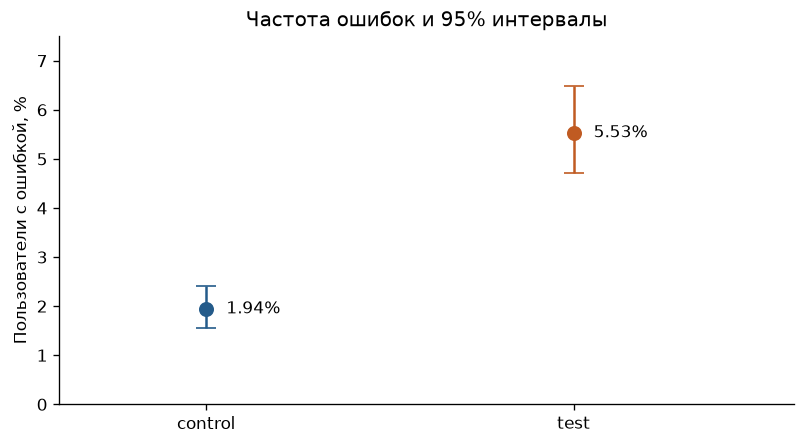

In [10]:
print(f'Ошибки control: {guardrail["events_control"]} / {guardrail["n_control"]} = {guardrail["rate_control"]:.2%}')
print(f'Ошибки test: {guardrail["events_test"]} / {guardrail["n_test"]} = {guardrail["rate_test"]:.2%}')
print(f'Разница: {100 * guardrail["difference"]:.3f} п.п.')
print(f'95% ДИ разницы: [{100 * guardrail["ci_low"]:.3f}, {100 * guardrail["ci_high"]:.3f}] п.п.')
print(f'p-value: {guardrail["p_value"]:.3g}')
print('Рост ошибок обнаружен. Тест нужно остановить.' if guardrail_warning
      else 'Значимого роста ошибок не обнаружено.')

fig, ax = plt.subplots(figsize=(6.6, 3.6), layout='constrained')
rates = [guardrail['rate_control'], guardrail['rate_test']]
for i, group in enumerate(GROUPS):
    interval = error_intervals[i]
    ax.errorbar(i, 100 * rates[i],
                yerr=[[100 * (rates[i] - interval.low)], [100 * (interval.high - rates[i])]],
                fmt='o', color=COLORS[i], markersize=8, capsize=6)
    ax.annotate(f'{rates[i]:.2%}', (i, 100 * rates[i]), xytext=(12, 0),
                textcoords='offset points', va='center')
ax.set_xticks([0, 1], GROUPS)
ax.set_xlim(-0.4, 1.6)
ax.set_ylim(0, 7.5)
ax.set_ylabel('Пользователи с ошибкой, %')
ax.set_title('Частота ошибок и 95% интервалы')
plt.show()

частота ошибок выросла с 1,94% до 5,53%, то есть на 3,588 п.п. 95% интервал разницы от +2,606 до +4,569 п.п., p-value примерно 2,74 · 10⁻¹⁵. это основание для остановки независимо от результата по конверсии. в генераторе для вариантов заданы разные вероятности ошибки: 2% и 6%.

## 6. Платформы и множественные проверки

### Условие

Посчитайте эффект для каждого из трёх уровней platform. Примените поправку Бонферрони или FDR. Есть ли значимый эффект после поправки? Объясните, почему сегменты не должны быть единственным основанием для запуска.

### Решение

проверяются все три платформы, без выбора самой удачной после просмотра результатов. для каждой платформы используется тот же Z-тест. в этой выборке даже в самой маленькой группе есть 16 конверсий, поэтому проверка минимальных частот выполняется.

семейство состоит из трёх сравнений. поправка Бонферрони умножает каждое p-value на 3 и ограничивает результат единицей. эквивалентный порог для исходного p-value равен `0.05 / 3`. поправка относится только к этим трём проверкам, она не исправляет рандомизацию, состав групп или подглядывание.

в исходном коде конверсии пользователей test на платформе 2 заменяются новой случайной величиной с вероятностью 0,2. это искусственное изменение исходов, а не просто случайная находка из многих тестов. объявленная переменная `true_effect = 0` в расчётах генератора не используется. поэтому фактические данные не описывают чистый нулевой эффект во всех сегментах.

### Код

In [11]:
segment_rows = []
for platform in [0, 1, 2]:
    part = df.loc[df.platform == platform]
    result = compare_proportions(part, 'converted')
    segment_rows.append({'platform': platform, **result})
segments = pd.DataFrame(segment_rows)

# поправка охватывает все три заранее перечисленные платформы
segments['p_bonferroni'] = np.minimum(1.0, 3 * segments.p_value)
segments['significant'] = segments.p_bonferroni < ALPHA
significant_platforms = segments.loc[segments.significant, 'platform'].astype(int).tolist()

### Проверка

,Платформа,n control,n test,Конверсия control,Конверсия test,"Разница, п.п.",Lift,p-value,p Бонферрони,После поправки
0,0,2463,1575,10.64%,11.24%,0.601,5.65%,0.549784,1.000000,не значимо
1,1,1379,862,10.30%,13.69%,3.392,32.94%,0.014718,0.044154,значимо
2,2,175,131,9.14%,22.90%,13.758,150.48%,0.000862,0.002587,значимо


Платформы с p Бонферрони < 0.05: [1, 2]


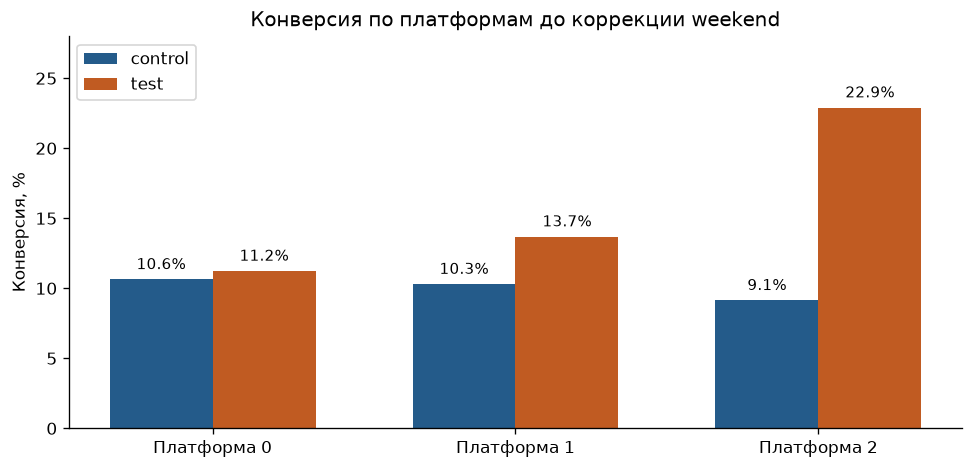

In [12]:
segment_view = pd.DataFrame({
    'Платформа': segments.platform,
    'n control': segments.n_control,
    'n test': segments.n_test,
    'Конверсия control': segments.rate_control.map('{:.2%}'.format),
    'Конверсия test': segments.rate_test.map('{:.2%}'.format),
    'Разница, п.п.': (100 * segments.difference).round(3),
    'Lift': segments.lift.map('{:.2%}'.format),
    'p-value': segments.p_value.map('{:.6f}'.format),
    'p Бонферрони': segments.p_bonferroni.map('{:.6f}'.format),
    'После поправки': segments.significant.map({True: 'значимо', False: 'не значимо'}),
})
display(segment_view)
print(f'Платформы с p Бонферрони < 0.05: {significant_platforms}')

fig, ax = plt.subplots(figsize=(8, 3.8), layout='constrained')
positions = np.arange(3)
width = 0.34
for offset, group, color, rates in [
    (-width / 2, 'control', COLORS[0], segments.rate_control),
    (width / 2, 'test', COLORS[1], segments.rate_test),
]:
    bars = ax.bar(positions + offset, 100 * rates, width=width, label=group, color=color)
    ax.bar_label(bars, labels=[f'{x:.1%}' for x in rates], padding=4, fontsize=9)
ax.set_xticks(positions, ['Платформа 0', 'Платформа 1', 'Платформа 2'])
ax.set_ylim(0, 28)
ax.set_ylabel('Конверсия, %')
ax.set_title('Конверсия по платформам до коррекции weekend')
ax.legend()
plt.show()

после Бонферрони формально значимыми остаются платформы 1 и 2: p-value 0,044154 и 0,002587. для платформы 0 скорректированное p-value равно 1. на платформе 2 наблюдается разница +13,758 п.п., но там только 306 пользователей и есть искусственная подмена конверсий в генераторе.

эти проверки описывают нескорректированные различия внутри платформ. они не устраняют дисбаланс weekend и рост ошибок. кроме того, значимость в одном сегменте и незначимость в другом сама по себе не доказывает различие эффектов между сегментами. для такого вывода нужен отдельный тест взаимодействия. запуск по этим сегментным находкам не обоснован.

## 7. Время входа и проверка peeking

### Условие

Проверьте связь между entry_time и вариантом. Если пользователи test систематически входят позже, это может указывать на остановку по времени. Постройте распределения entry_time по группам и сделайте вывод.

### Решение

сравниваются среднее, медиана и распределения времени. двусторонний U-тест Манна-Уитни проверяет различие рангов. он выбран как проверка возможного сдвига времени без предположения о нормальном распределении.

гистограмма показывает долю пользователей в каждом часовом интервале. второй график показывает долю пользователей, вошедших не позднее указанного времени. нормировка нужна, потому что размеры групп разные.

связь времени и варианта сама по себе не доказывает peeking. подглядывание означает просмотр промежуточных результатов и решение об остановке на их основе. для проверки нужны история просмотров, значения метрик в эти моменты и правило остановки. таких данных в CSV нет.

### Код

In [13]:
entry_result = mannwhitneyu(
    test.entry_time, control.entry_time,
    alternative='two-sided', method='asymptotic',
)
p_entry = float(entry_result.pvalue)
entry_warning = p_entry < ALPHA
entry_summary = df.groupby('variant').entry_hours.agg(['mean', 'median']).reindex(GROUPS)
entry_diff_minutes = 60 * (test.entry_hours.mean() - control.entry_hours.mean())

### Проверка

,"Среднее, ч","Медиана, ч"
variant,,
control,12.109,12.136
test,12.061,12.106


Разница средних test - control: -2.844 минуты
U-статистика: 5136326.0
p-value: 0.775063
Значимого сдвига времени входа не обнаружено.


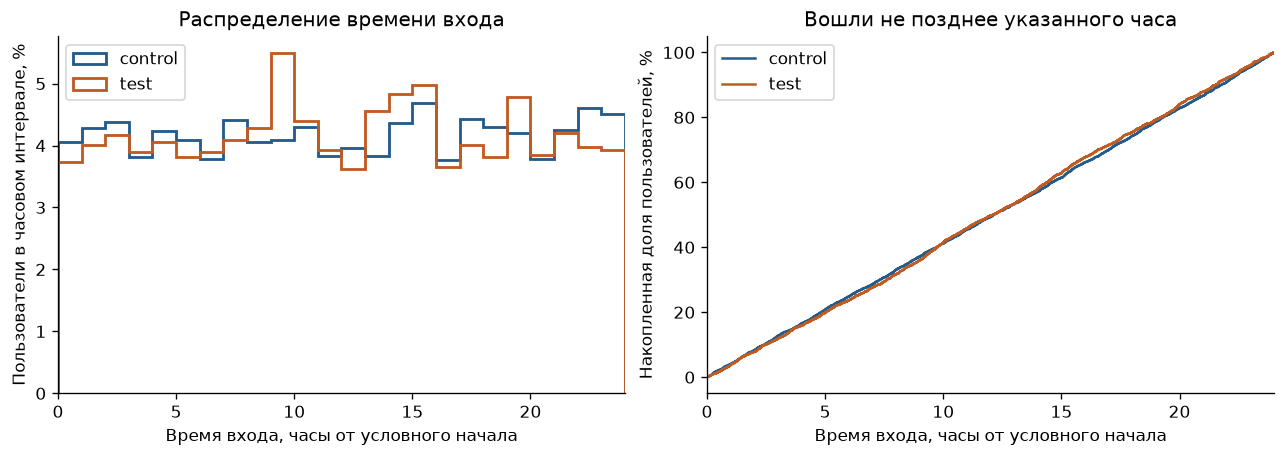

In [14]:
display(entry_summary.rename(columns={'mean': 'Среднее, ч', 'median': 'Медиана, ч'}).round(3))
print(f'Разница средних test - control: {entry_diff_minutes:.3f} минуты')
print(f'U-статистика: {entry_result.statistic:.1f}')
print(f'p-value: {p_entry:.6f}')
print('Различие времени входа обнаружено.' if entry_warning
      else 'Значимого сдвига времени входа не обнаружено.')

fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.7), layout='constrained')
bins = np.linspace(0, 24, 25)
for group, color in zip(GROUPS, COLORS):
    hours = df.loc[df.variant == group, 'entry_hours'].to_numpy()
    # доли вместо количества позволяют сравнить группы разного размера
    axes[0].hist(hours, bins=bins, weights=np.full(len(hours), 100 / len(hours)),
                 histtype='step', linewidth=1.7, label=group, color=color)
    ordered = np.sort(hours)
    cumulative = np.arange(1, len(ordered) + 1) / len(ordered)
    axes[1].step(ordered, 100 * cumulative, where='post', label=group, color=color)
axes[0].set_ylabel('Пользователи в часовом интервале, %')
axes[0].set_title('Распределение времени входа')
axes[1].set_ylabel('Накопленная доля пользователей, %')
axes[1].set_title('Вошли не позднее указанного часа')
for ax in axes:
    ax.set_xlabel('Время входа, часы от условного начала')
    ax.set_xlim(0, 24)
    ax.legend()
plt.show()

p-value равно 0,775063. значимого временного сдвига не найдено, test в среднем вошёл примерно на 2,84 минуты раньше. это не доказывает отсутствие подглядывания.

в исходном коде первое назначение `variant = np.where(time_of_entry > 0.4, ...)` действительно связано со временем. затем оно полностью заменяется через `np.random.choice()`, а следующая корректировка использует weekend. реального цикла промежуточных тестов и остановки по p-value в генераторе нет. поэтому заявленный в комментарии механизм peeking не реализован. по CSV установить нарушение протокола остановки нельзя.

## 8. Коррекция дисбаланса weekend

### Условие

Предложите коррекцию нарушений или обоснуйте необходимость перезапуска. Если данные можно скорректировать, используйте IPW, CUPED, стратификацию или регрессию. Покажите изменение оценки эффекта после коррекции. Этот пункт обязателен для зачёта.

### Решение

применяется стратификация по weekend. отдельно считаются конверсии в будни и выходные, затем обе группы приводятся к одному составу: 69,72% будней и 30,28% выходных. это доли во всей исходной выборке.

для каждого варианта скорректированная конверсия равна `w0 * p0 + w1 * p1`. разница этих двух величин показывает сравнение при одинаковом составе по weekend. пользователи не удаляются, конверсии не изменяются.

95% интервал строится для взвешенной разницы. в дисперсию входят квадраты весов и отдельные дисперсии групп внутри каждого слоя. веса считаются фиксированным целевым составом этой выборки. дополнительное p-value является приближённым тестом Уолда для этой скорректированной разницы.

weekend не зависит от варианта по смыслу признака. обе группы присутствуют в каждом слое. при отсутствии других смешивающих факторов такое сравнение могло бы убрать смещение из-за weekend. здесь оно используется как диагностическая коррекция: SRM, рост ошибок и искусственную подмену конверсий на платформе 2 оно не исправляет. неизвестный протокол остановки тоже не восстанавливается.

### Код

In [15]:
def standardize_weekend(data):
    rows = []
    rate_control = 0.0
    rate_test = 0.0
    variance_difference = 0.0

    for weekend, part in data.groupby('weekend', sort=True):
        group_stats = part.groupby('variant').converted.agg(['sum', 'size']).reindex(GROUPS)
        if group_stats.isna().any().any():
            raise ValueError('В каждом значении weekend нужны обе группы.')
        n_control = int(group_stats.loc['control', 'size'])
        n_test = int(group_stats.loc['test', 'size'])
        p_control = group_stats.loc['control', 'sum'] / n_control
        p_test = group_stats.loc['test', 'sum'] / n_test

        # одинаковый вес слоя применяется к обеим группам
        weight = len(part) / len(data)
        rate_control += weight * p_control
        rate_test += weight * p_test

        # при фиксированных весах дисперсия взвешенной суммы содержит квадрат веса
        layer_variance = p_control * (1 - p_control) / n_control + p_test * (1 - p_test) / n_test
        variance_difference += weight ** 2 * layer_variance
        rows.append({
            'weekend': int(weekend), 'weight': weight,
            'n_control': n_control, 'n_test': n_test,
            'rate_control': p_control, 'rate_test': p_test,
            'difference': p_test - p_control,
        })

    difference = rate_test - rate_control
    standard_error = np.sqrt(variance_difference)
    result = {
        'rate_control': float(rate_control), 'rate_test': float(rate_test),
        'difference': float(difference), 'lift': float(rate_test / rate_control - 1),
        'ci_low': float(difference - Z_CRIT * standard_error),
        'ci_high': float(difference + Z_CRIT * standard_error),
        'p_value': float(2 * norm.sf(abs(difference / standard_error))),
    }
    return pd.DataFrame(rows), result

strata, adjusted = standardize_weekend(df)

### Проверка

,weekend,Вес,n control,n test,Конверсия control,Конверсия test,"Разница, п.п."
0,0,69.72%,3490,1101,9.60%,10.26%,0.665
1,1,30.28%,527,1467,16.13%,14.45%,-1.678


,Оценка,Конверсия control,Конверсия test,"Разница, п.п.",Lift,"95% ДИ, п.п.",p-value
0,До коррекции,10.46%,12.66%,2.200,21.04%,"[0.604, 3.797]",0.005974
1,После коррекции weekend,11.58%,11.53%,-0.045,-0.39%,"[-1.841, 1.752]",0.961076


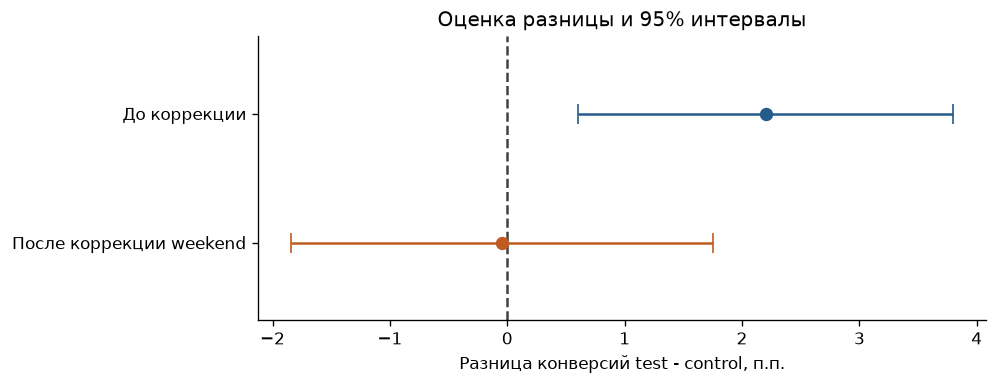

In [16]:
# веса образуют полный состав выборки, каждый слой содержит обе группы
assert np.isclose(strata.weight.sum(), 1)
assert (strata[['n_control', 'n_test']] > 0).all().all()
strata_view = pd.DataFrame({
    'weekend': strata.weekend,
    'Вес': strata.weight.map('{:.2%}'.format),
    'n control': strata.n_control, 'n test': strata.n_test,
    'Конверсия control': strata.rate_control.map('{:.2%}'.format),
    'Конверсия test': strata.rate_test.map('{:.2%}'.format),
    'Разница, п.п.': (100 * strata.difference).round(3),
})
display(strata_view)

comparison_rows = []
for label, result in [('До коррекции', primary), ('После коррекции weekend', adjusted)]:
    comparison_rows.append({
        'Оценка': label,
        'Конверсия control': f'{result["rate_control"]:.2%}',
        'Конверсия test': f'{result["rate_test"]:.2%}',
        'Разница, п.п.': round(100 * result['difference'], 3),
        'Lift': f'{result["lift"]:.2%}',
        '95% ДИ, п.п.': f'[{100 * result["ci_low"]:.3f}, {100 * result["ci_high"]:.3f}]',
        'p-value': f'{result["p_value"]:.6f}',
    })
display(pd.DataFrame(comparison_rows))

fig, ax = plt.subplots(figsize=(8.2, 3.1), layout='constrained')
for i, result in enumerate([primary, adjusted]):
    value = 100 * result['difference']
    lower = 100 * result['ci_low']
    upper = 100 * result['ci_high']
    ax.errorbar(value, i, xerr=[[value - lower], [upper - value]],
                fmt='o', color=COLORS[i], capsize=6, markersize=7)
ax.axvline(0, color='#414141', linestyle='--')
ax.set_yticks([0, 1], ['До коррекции', 'После коррекции weekend'])
ax.set_ylim(1.6, -0.6)
ax.set_xlabel('Разница конверсий test - control, п.п.')
ax.set_title('Оценка разницы и 95% интервалы')
plt.show()

после приведения к одному составу конверсии равны 11,58% в control и 11,53% в test. разница изменилась с +2,200 до -0,045 п.п., lift с +21,04% до -0,39%. 95% интервал скорректированной разницы от -1,841 до +1,752 п.п., p-value 0,961076.

после коррекции данных недостаточно для утверждения о положительном эффекте. интервал включает и ухудшение, и улучшение, поэтому равенство вариантов не доказано. коррекция показывает влияние состава групп, но не делает исходный эксперимент пригодным для запуска фичи.

## 9. Продуктовое решение

### Условие

Выберите rollout, не rollout или повторить с изменениями. Учтите защитную метрику, SRM, peeking и скорректированный эффект. Обоснуйте решение числами.

### Решение

p-value первичной метрики оценивается после всех проверок. в исходном сравнении оно меньше 0,05, но группы имеют разный состав. после коррекции weekend оценка близка к нулю, а интервал остаётся широким.

рост ошибок является отдельной причиной остановки. для текущего решения достаточно уже обнаруженных SRM, дисбаланса weekend и ухудшения защитной метрики. peeking не считается доказанным, его статус остаётся неизвестным без журнала анализа.

### Код

In [17]:
decision_facts = pd.DataFrame([
    {'Проверка': 'SRM', 'Результат': f'p = {p_srm:.3g}, группы 4017 / 2568'},
    {'Проверка': 'weekend', 'Результат': f'p = {p_weekend:.3g}, доли {weekend_control:.2%} / {weekend_test:.2%}'},
    {'Проверка': 'Ошибки', 'Результат': f'p = {guardrail["p_value"]:.3g}, частоты {guardrail["rate_control"]:.2%} / {guardrail["rate_test"]:.2%}'},
    {'Проверка': 'Платформы', 'Результат': f'После Бонферрони значимы {significant_platforms}, до коррекции weekend'},
    {'Проверка': 'Время входа', 'Результат': f'p = {p_entry:.3f}, история просмотров результатов отсутствует'},
    {'Проверка': 'Коррекция weekend', 'Результат': f'Разница {100 * adjusted["difference"]:.3f} п.п., p = {adjusted["p_value"]:.3f}'},
])
# решение относится к исходному эксперименту, коррекция не отменяет его нарушений
decision = 'Повторить с изменениями'

### Проверка

In [18]:
display(decision_facts)
print(decision)
print('Текущую версию фичи не запускать на всех пользователей.')

,Проверка,Результат
0,SRM,"p = 2.58e-71, группы 4017 / 2568"
1,weekend,"p = 5.25e-290, доли 13.12% / 57.13%"
2,Ошибки,"p = 2.74e-15, частоты 1.94% / 5.53%"
3,Платформы,"После Бонферрони значимы [1, 2], до коррекции weekend"
4,Время входа,"p = 0.775, история просмотров результатов отсутствует"
5,Коррекция weekend,"Разница -0.045 п.п., p = 0.961"


Повторить с изменениями
Текущую версию фичи не запускать на всех пользователей.


**Повторить с изменениями.** в текущем тесте ошибки выросли с 1,94% до 5,53%. группы 4017/2568 нарушают план 50/50, а доля выходных отличается на 44,01 п.п. после коррекции разница конверсий равна -0,045 п.п. с 95% интервалом от -1,841 до +1,752 п.п. оснований для rollout нет.

перед новым тестом нужно:

1. Назначать вариант с вероятностью 0,5 независимо от weekend и времени входа. Сохранять назначение пользователя и проверить его через A/A.
2. Устранить причину ошибок в test и проверить корректность событий конверсии на платформе 2. При построении тестовых данных убрать искусственную подмену исходов. Существующий CSV не исправлять задним числом.
3. Заранее зафиксировать основную метрику, допустимое ухудшение ошибок, размер выборки и срок. Для промежуточных просмотров использовать заранее выбранный последовательный метод, либо анализировать результат только в конце фиксированного теста.
4. Задать список сегментов и правило множественных проверок до анализа. Новый эксперимент проводить на новых данных и сохранять журнал просмотров и остановки.